# 01 — Análise exploratória dos dados (EDA)

**Objetivo:** entender o corpus antes de modelar e justificar as decisões de tratamento do pipeline
(`src/data/preprocessing.py`).

**Dataset:** [Medical Abstracts Text Classification Corpus](https://github.com/sebischair/Medical-Abstracts-TC-Corpus)
— resumos médicos em inglês rotulados em 5 categorias de doença.

O notebook usa as **mesmas funções do pipeline** (`clean_text`, `map_labels`, `params.yaml`), então o que
se vê aqui é exatamente o que o treino recebe.

| Seção | Pergunta |
|---|---|
| 1 | Como é o dado bruto? |
| 2 | As classes são balanceadas? |
| 3 | Há duplicatas? Elas são perigosas? |
| 4 | Qual o tamanho dos textos? |
| 5 | O vocabulário separa as classes? O rótulo de urgência é confiável? |
| 6 | Conclusões → decisões do projeto |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.config import LABELS, TARGET_COLUMN, TEXT_COLUMN, load_params
from src.data.preprocessing import map_labels
from src.data.text import clean_text

RAW_PATH = ROOT / "data" / "raw" / "medical_abstracts.csv"
if not RAW_PATH.exists():
    from src.data.download import download_dataset

    download_dataset(RAW_PATH.parent)

params = load_params()
CATEGORY_NAMES = {
    1: "Neoplasias",
    2: "Sistema digestivo",
    3: "Sistema nervoso",
    4: "Cardiovascular",
    5: "Condições gerais",
}
# Categorical slots 1-3 of the reference palette (validated for color-vision deficiency),
# assigned in the fixed order of LABELS: normal, atencao, urgente.
CLASS_COLORS = dict(zip(LABELS, ["#2a78d6", "#eb6834", "#1baf7a"], strict=True))
SINGLE = "#2a78d6"

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#9a9993",
        "axes.labelcolor": "#52514e",
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.titleweight": "bold",
        "axes.titlesize": 11,
    }
)


def label_bars(ax, bars, fmt="{:,.0f}", horizontal=False):
    for bar in bars:
        value = bar.get_width() if horizontal else bar.get_height()
        text = fmt.format(value).replace(",", ".")
        if horizontal:
            ax.annotate(text, (value, bar.get_y() + bar.get_height() / 2), xytext=(4, 0),
                        textcoords="offset points", va="center", fontsize=9, color="#0b0b0b")
        else:
            ax.annotate(text, (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 3),
                        textcoords="offset points", ha="center", fontsize=9, color="#0b0b0b")

## 1. Visão geral do dado bruto

In [2]:
raw = pd.read_csv(RAW_PATH)
print(f"Linhas: {len(raw):,}".replace(",", "."), "| Colunas:", list(raw.columns))
print("Nulos por coluna:", raw.isna().sum().to_dict())
for _, row in raw.sample(3, random_state=7).iterrows():
    print(f"\n[categoria {row['condition_label']} - {CATEGORY_NAMES[row['condition_label']]}]")
    print(row["medical_abstract"][:300], "...")

Linhas: 14.438 | Colunas: ['condition_label', 'medical_abstract']
Nulos por coluna: {'condition_label': 0, 'medical_abstract': 0}

[categoria 4 - Cardiovascular]
Effect of naproxen and sulindac on blood pressure response to atenolol. Twenty-eight patients with mild to moderate essential hypertension well controlled by atenolol entered a five-week, double-blind, placebo-controlled trial of the effects of sulindac and naproxen on blood pressure (BP) control. A ...

[categoria 4 - Cardiovascular]
Clinical association of autoantibodies to fibrillarin with diffuse scleroderma and disseminated telangiectasia. Circulating autoantibodies against a variety of nuclear and nucleolar antigens are characteristic serologic findings in systemic scleroderma. Some of these antibodies correlate with clinic ...

[categoria 5 - Condições gerais]
The significance of gastrinomas found in peripancreatic lymph nodes. A patient with Zollinger-Ellison syndrome (ZES) was found to have a solitary, extrapancreatic

**Leitura:** 14.438 textos, sem nulos. Os textos são **resumos de artigos científicos** (estudos,
coortes, até experimentos em animais), não laudos de exame — um ponto que vai pesar na seção 5.

## 2. Distribuição das classes

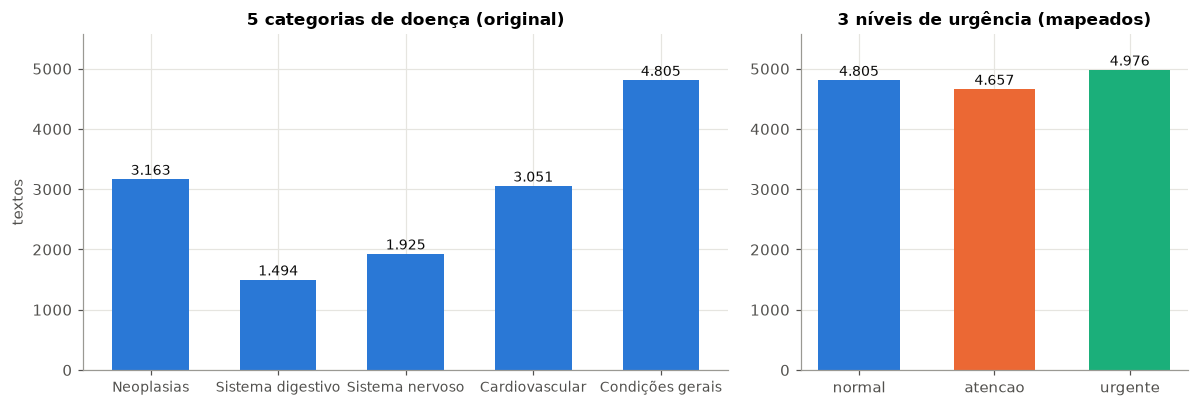

,textos,proporção
urgency,,
normal,4805,0.333
atencao,4657,0.323
urgente,4976,0.345


In [3]:
raw["category"] = raw["condition_label"].map(CATEGORY_NAMES)
mapping = {int(k): v for k, v in params["label_mapping"].items()}
raw["urgency"] = raw["condition_label"].map(mapping)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [5, 3]})

counts = raw["category"].value_counts().reindex(CATEGORY_NAMES.values())
bars = axes[0].bar(counts.index, counts.values, color=SINGLE, width=0.6)
label_bars(axes[0], bars)
axes[0].set_title("5 categorias de doença (original)")
axes[0].set_ylabel("textos")
axes[0].tick_params(axis="x", labelsize=9)

urgency = raw["urgency"].value_counts().reindex(LABELS)
bars = axes[1].bar(urgency.index, urgency.values, color=[CLASS_COLORS[c] for c in LABELS], width=0.6)
label_bars(axes[1], bars)
axes[1].set_title("3 níveis de urgência (mapeados)")
top = max(counts.max(), urgency.max()) * 1.12  # same scale (both panels count texts) + room for labels
for ax in axes:
    ax.set_ylim(0, top)
fig.tight_layout()
plt.show()

summary = pd.DataFrame({"textos": urgency, "proporção": (urgency / urgency.sum()).round(3)})
summary

**Leitura:** as 5 categorias são desbalanceadas (de 1.494 a 4.805), mas o mapeamento
(`label_mapping` no `params.yaml`) junta duas categorias em `urgente` (nervoso + cardiovascular) e duas
em `atencao` (neoplasias + digestivo), resultando em **3 classes equilibradas (~1/3 cada)**.

→ Decisão: acurácia é uma métrica honesta aqui, mas usamos **macro-F1** (média das classes) como
métrica principal e `class_weight="balanced"` por segurança.

## 3. Duplicatas

In [4]:
raw["clean"] = raw["medical_abstract"].map(clean_text)
dup_rows = raw["clean"].duplicated().sum()
labels_per_text = raw.groupby("clean")["condition_label"].nunique()
conflicting = int((labels_per_text > 1).sum())

dataset = map_labels(raw, params)  # what the pipeline keeps
print(f"Textos brutos:              {len(raw):>6,}".replace(",", "."))
print(f"Linhas duplicadas:          {dup_rows:>6,} ({dup_rows / len(raw):.0%})".replace(",", "."))
print(f"Textos com rótulos diferentes: {conflicting:>3,}".replace(",", "."))
print(f"Após deduplicação:          {len(dataset):>6,}".replace(",", "."))

conflict_texts = labels_per_text[labels_per_text > 1].index
pairs = (
    raw[raw["clean"].isin(conflict_texts)]
    .groupby("clean")["category"]
    .apply(lambda s: " + ".join(sorted(set(s))))
    .value_counts()
    .head(5)
)
pairs.rename("textos").to_frame()

Textos brutos:              14.438
Linhas duplicadas:           3.211 (22%)
Textos com rótulos diferentes: 2.929
Após deduplicação:          11.227


,textos
category,
Cardiovascular + Condições gerais,738
Condições gerais + Neoplasias,486
Condições gerais + Sistema digestivo,475
Condições gerais + Sistema nervoso,446
Neoplasias + Sistema nervoso,139


**Leitura:** **22% das linhas (3.211) são duplicadas** — e **91% delas (2.929 textos) aparecem com
categorias diferentes**. Quase todos os pares envolvem **"Condições gerais"** junto de uma doença
específica: o corpus é, na prática, **multi-rótulo** (o mesmo resumo é "condição geral" *e*, por exemplo,
"cardiovascular").

→ Decisão: `map_labels` remove duplicatas **antes** do split. Sem isso, o mesmo texto poderia cair no
treino e no teste, e o modelo seria avaliado em textos que já "decorou" (*data leakage*), inflando as
métricas.

⚠️ **Limitação:** ao deduplicar, a primeira ocorrência é mantida, então nos 2.929 textos conflitantes o
rótulo que sobra é arbitrário. **Melhoria futura:** resolver o conflito priorizando a categoria
específica sobre "Condições gerais" (que vira `normal`), o que deve reduzir os quadros agudos
rotulados como `normal` (seção 5).

## 4. Tamanho dos textos

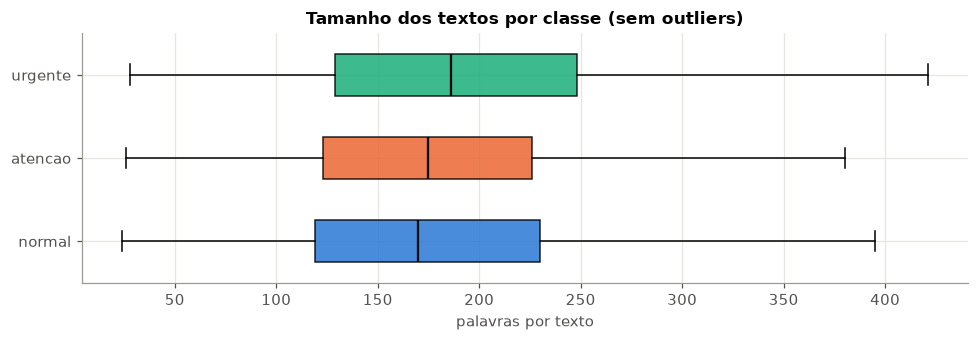

Maior texto: 3.998 caracteres


,média,mediana,p95,máximo
label,,,,
normal,176,170,298,528
atencao,177,175,303,422
urgente,188,186,305,596


In [5]:
dataset["words"] = dataset[TEXT_COLUMN].str.split().str.len()
dataset["chars"] = dataset[TEXT_COLUMN].str.len()

fig, ax = plt.subplots(figsize=(9, 3.2))
data = [dataset.loc[dataset[TARGET_COLUMN] == c, "words"] for c in LABELS]
box = ax.boxplot(data, orientation="horizontal", tick_labels=LABELS, widths=0.5, patch_artist=True,
                 showfliers=False, medianprops={"color": "#0b0b0b", "linewidth": 1.5})
for patch, c in zip(box["boxes"], LABELS, strict=True):
    patch.set_facecolor(CLASS_COLORS[c])
    patch.set_alpha(0.85)
ax.set_xlabel("palavras por texto")
ax.set_title("Tamanho dos textos por classe (sem outliers)")
fig.tight_layout()
plt.show()

stats = dataset.groupby(TARGET_COLUMN)["words"].describe(percentiles=[0.5, 0.95])
stats = stats.loc[LABELS, ["mean", "50%", "95%", "max"]].round(0).astype(int)
stats.columns = ["média", "mediana", "p95", "máximo"]
print(f"Maior texto: {dataset['chars'].max():,} caracteres".replace(",", "."))
stats

**Leitura:** os textos têm mediana de **170 a 186 palavras** e p95 em torno de 300, com
distribuições parecidas entre as classes — o **tamanho não denuncia a classe**, então o modelo precisa
aprender pelo conteúdo. O maior texto tem **3.998 caracteres**.

→ Decisão: o limite da API (`MAX_TEXT_LENGTH = 20000` caracteres) cobre com folga qualquer texto real e
barra entradas abusivas. Textos curtos e longos são tratados igualmente pelo TF-IDF (normalização L2).

## 5. Vocabulário: o que diferencia as classes?

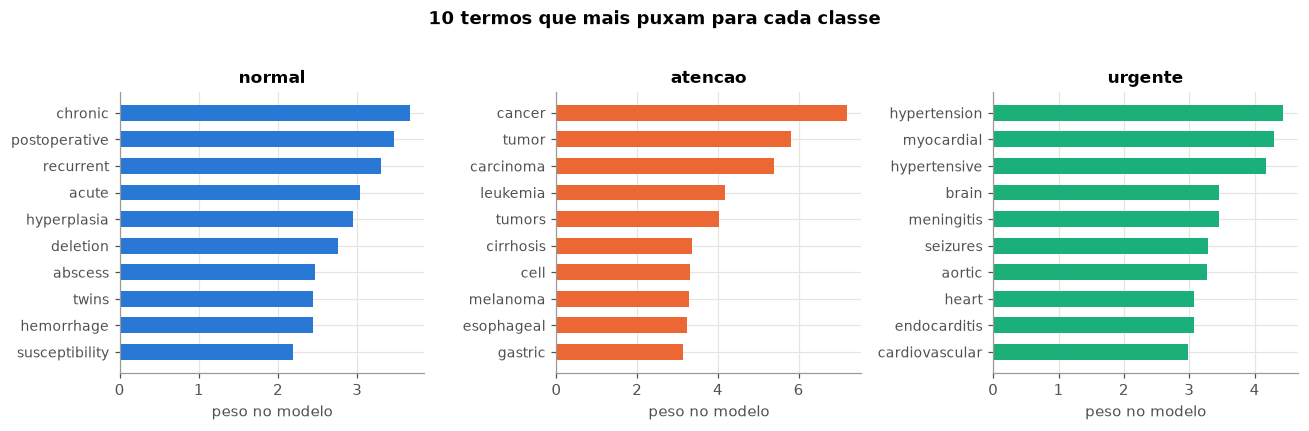

In [6]:
from src.models.train import build_pipeline

pipe = build_pipeline(params["model"])
pipe.fit(dataset[TEXT_COLUMN], dataset[TARGET_COLUMN])
terms = pipe.named_steps["tfidf"].get_feature_names_out()
clf = pipe.named_steps["clf"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, c in zip(axes, LABELS, strict=True):
    weights = pd.Series(clf.coef_[list(clf.classes_).index(c)], index=terms).nlargest(10)[::-1]
    bars = ax.barh(weights.index, weights.values, color=CLASS_COLORS[c], height=0.6)
    ax.set_title(f"{c}")
    ax.tick_params(axis="y", labelsize=9)
    ax.set_xlabel("peso no modelo")
fig.suptitle("10 termos que mais puxam para cada classe", fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()

**Leitura:** `atencao` (oncologia: *cancer, tumor, carcinoma*) e `urgente` (cardio/neuro:
*myocardial, meningitis, seizures*) têm vocabulário claro. Mas em `normal` aparecem termos clinicamente
**agudos** — *hemorrhage, bleeding, acute, abscess*. Isso é um sinal do **rótulo proxy**: a categoria
"condições patológicas gerais" mistura achados graves que não se encaixam nas outras quatro.

Medindo diretamente:

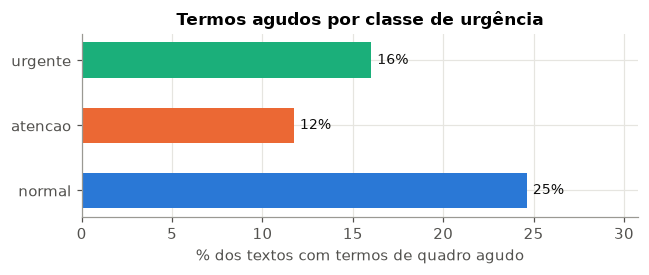

In [7]:
ACUTE = r"\b(?:acute|hemorrhage|haemorrhage|bleeding|abscess|emergency|sepsis|shock)\b"
share = (
    dataset.assign(acute=dataset[TEXT_COLUMN].str.contains(ACUTE, regex=True))
    .groupby(TARGET_COLUMN)["acute"].mean().reindex(LABELS)
)

fig, ax = plt.subplots(figsize=(6, 2.6))
bars = ax.barh(share.index, share.values * 100, color=[CLASS_COLORS[c] for c in LABELS], height=0.55)
label_bars(ax, bars, fmt="{:.0f}%", horizontal=True)
ax.set_xlabel("% dos textos com termos de quadro agudo")
ax.set_title("Termos agudos por classe de urgência")
ax.set_xlim(0, max(share.values * 100) * 1.25)
fig.tight_layout()
plt.show()

**Leitura:** **24,6% dos textos `normal` têm termos de quadro agudo — mais que os `urgente` (16,0%)**
e os `atencao` (11,7%). A classe "normal" tem mais linguagem aguda que a "urgente": é a assinatura do
rótulo proxy e dos conflitos da seção 3. O modelo aprende fielmente o que o rótulo diz, então
"hemorragia aguda" tende a ser classificada como `normal`.

→ Decisão: o mapeamento é documentado como **limitação principal** no [model card](../docs/model_card.md).
Em produção real, a correção seria re-rotular com médicos (ou ao menos retirar da classe `normal` os
textos com quadro agudo). Também explica por que `normal` tem o pior F1 (0,62).

## 6. Conclusões → decisões do projeto

| Achado | Decisão no pipeline | Onde |
|---|---|---|
| 14.438 textos em inglês, sem nulos | Usar o corpus completo; API documentada como "textos em inglês" | `params.yaml`, README |
| 5 categorias desbalanceadas → 3 classes equilibradas após o mapeamento | Macro-F1 como métrica principal; `class_weight="balanced"` | `src/evaluation/metrics.py`, `src/models/train.py` |
| 22% de duplicatas; 91% delas com categorias conflitantes (corpus multi-rótulo) | Deduplicar **antes** do split, para evitar *data leakage*; resolução do conflito fica como melhoria futura | `map_labels` |
| Proporção das classes precisa ser preservada no teste | Split 80/20 **estratificado** com seed fixa | `split_dataset` |
| Tamanho do texto não separa as classes; maior texto tem 3.998 caracteres | Modelo baseado em conteúdo (TF-IDF); limite de 20.000 caracteres na API | `src/api/main.py` |
| Acentos/maiúsculas variam; ONNX só entende ASCII | `clean_text` (ASCII, minúsculas, espaços) idêntico no treino e na API | `src/data/text.py` |
| 24,6% dos textos `normal` têm termos agudos (mais que `urgente`, 16,0%) | Documentado como limitação do rótulo proxy; recall de `urgente` vigiado no champion × challenger | `docs/model_card.md`, `promotion` no `params.yaml` |
| Corpus científico, não laudos | Projeto demonstra o ciclo de MLOps; produção real exigiria laudos rotulados pelo hospital | model card |